In [16]:
import sys
print(sys.executable)

d:\Real-Time Acceleration for Medical Image Processing\venv\Scripts\python.exe


In [17]:
from src.io.loader import load_rf

rf_file = r"D:\Real-Time Acceleration for Medical Image Processing\7986407\CIRS073_RUMC\CIRS073_RUMC\hypo_lesion2\USDATA_20210624113900411.mat"

rf = load_rf(rf_file)

print(rf.shape)

(75, 1, 128, 2944)


In [18]:
from src.config import C, FS, PITCH, ANGLES_DEG

print(C)
print(FS)
print(PITCH)
print(ANGLES_DEG[:5])

1540.0
31250000.0
0.0001953
[-16.         -15.56756757 -15.13513514 -14.7027027  -14.27027027]


In [19]:
import src
print(src.__file__)

d:\Real-Time Acceleration for Medical Image Processing\src\__init__.py


In [20]:
from src.config import C, FS, PITCH

print(C)
print(FS)

1540.0
31250000.0


In [21]:
import os
import sys

print("Current working directory:")
print(os.getcwd())

print("\nPython executable:")
print(sys.executable)

Current working directory:
d:\Real-Time Acceleration for Medical Image Processing

Python executable:
d:\Real-Time Acceleration for Medical Image Processing\venv\Scripts\python.exe


In [22]:
from pathlib import Path

print("\nProject root contains:")
for p in Path(".").iterdir():
    print(p)


Project root contains:
Dataset_BUSI_with_GT
Image_Reconstruction
venv
.venv
7986407
requirements.txt
notebooks
src
test.ipynb


In [23]:
import sys

print("\nPython search path:")
for p in sys.path:
    print(p)


Python search path:
C:\Users\godli\AppData\Local\Programs\Python\Python311\python311.zip
C:\Users\godli\AppData\Local\Programs\Python\Python311\DLLs
C:\Users\godli\AppData\Local\Programs\Python\Python311\Lib
C:\Users\godli\AppData\Local\Programs\Python\Python311
d:\Real-Time Acceleration for Medical Image Processing\venv

d:\Real-Time Acceleration for Medical Image Processing\venv\Lib\site-packages


In [24]:
import src

print(src)
print(src.__file__)

<module 'src' from 'd:\\Real-Time Acceleration for Medical Image Processing\\src\\__init__.py'>
d:\Real-Time Acceleration for Medical Image Processing\src\__init__.py


In [25]:
from src.beamforming.geometry import element_positions

x = element_positions()

print(x.shape)
print(x[:5])
print(x[-5:])

(128,)
[-0.01240155 -0.01220625 -0.01201095 -0.01181565 -0.01162035]
[0.01162035 0.01181565 0.01201095 0.01220625 0.01240155]


In [26]:
from src.beamforming.grid import create_grid

X, Z = create_grid()

print(X.shape)
print(Z.shape)

print(X.min(), X.max())
print(Z.min(), Z.max())

(512, 256)
(512, 256)
-0.015 0.015
0.005 0.06


In [13]:
#Cell 1
rf_file = r"D:\Real-Time Acceleration for Medical Image Processing\7986407\CIRS073_RUMC\CIRS073_RUMC\hypo_lesion2\USDATA_20210624113900411.mat"

In [14]:
#Cell 2
from pathlib import Path

print(Path(rf_file).exists())

True


In [15]:
#Cell 3
from src.io.loader import load_rf
from src.beamforming.geometry import element_positions
from src.beamforming.grid import create_grid
from src.beamforming.delay_and_sum import beamform_single_angle

rf = load_rf(rf_file)

print(rf.shape)

(75, 1, 128, 2944)


In [16]:
#Cell 4
from src.beamforming.compound import coherent_compound
from src.config import ANGLES_DEG

rf0 = rf[37, 0, :, :]

print(rf0.shape)

(128, 2944)


In [17]:
#Cell 5
X, Z = create_grid()
elements = element_positions()

compound = coherent_compound(
    rf,
    X,
    Z,
    elements,
    ANGLES_DEG
)


In [10]:
rf.shape

(75, 1, 128, 2944)

In [11]:
from src.signal.envelope import envelope_detect, log_compress

env = envelope_detect(compound)

bmode = log_compress(env)

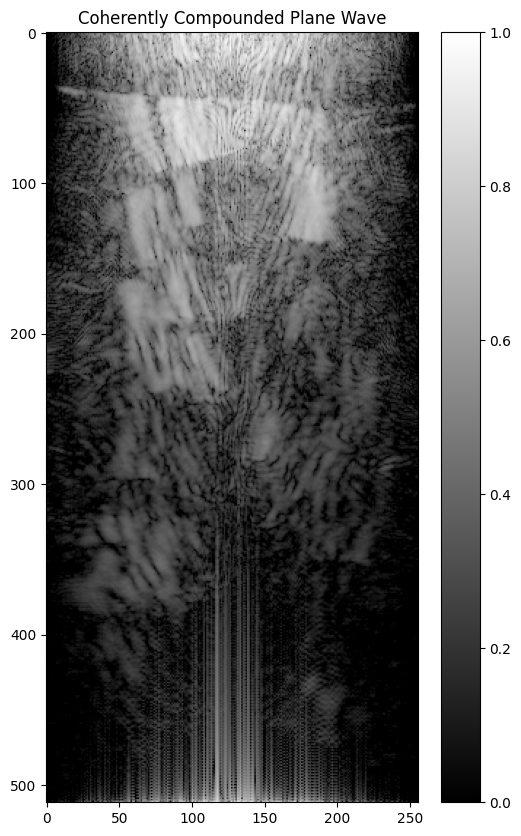

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 10))
plt.imshow(
    bmode,
    cmap="gray",
    aspect="auto",
    origin="upper",
)
plt.title("Coherently Compounded Plane Wave")
plt.colorbar()
plt.show()

In [ ]:
header = 

In [37]:
print(X.min(), X.max())
print(Z.min(), Z.max())

print(elements[0], elements[-1])

print(FS)
print(C)

-0.015 0.015
0.005 0.06
-0.01240155 0.01240155
31250000.0
1540.0


In [32]:
#Cell 6
X, Z = create_grid(
    nx=128,
    nz=256
)

In [33]:
#Cell 7
print(image.shape)
print(image.min(), image.max())

(512, 256)
-135043.39 122580.02


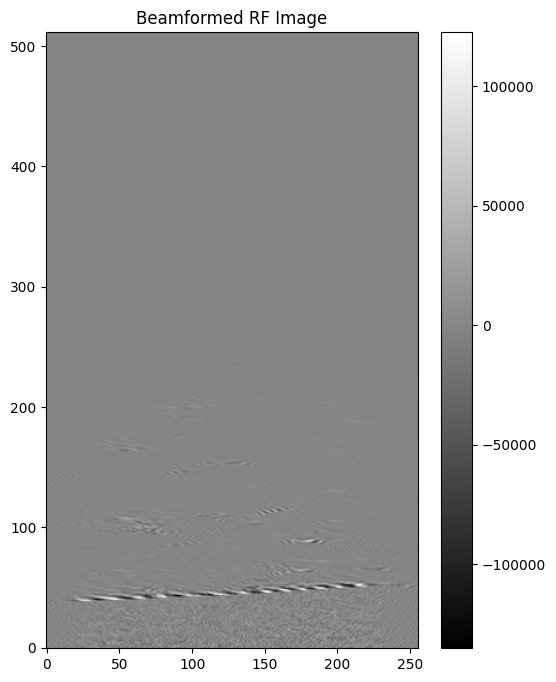

In [34]:
#Cell 8
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 8))

plt.imshow(
    image,
    cmap="gray",
    aspect="auto",
    origin="lower"
)

plt.colorbar()
plt.title("Beamformed RF Image")

plt.show()

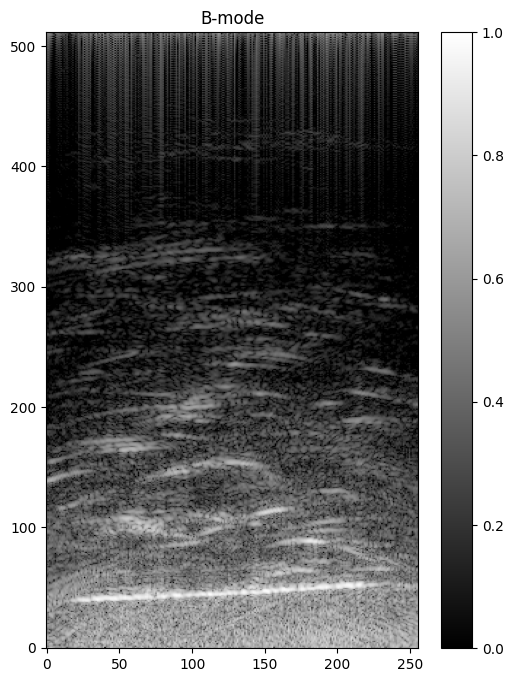

In [35]:
#Cell 9SS
from src.signal.envelope import envelope_detect, log_compress

env = envelope_detect(image)

bmode = log_compress(env)

plt.figure(figsize=(6,8))
plt.imshow(
    bmode,
    cmap="gray",
    origin="lower",
    aspect="auto"
)
plt.title("B-mode")
plt.colorbar()
plt.show()

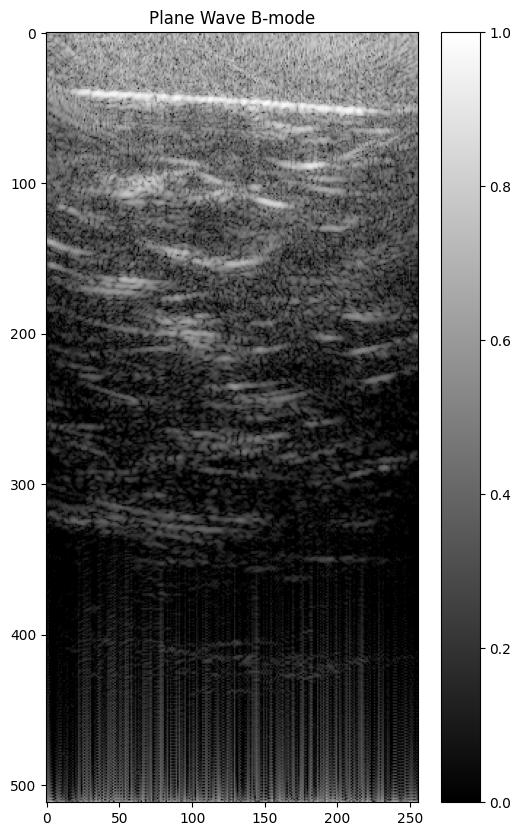

In [36]:
env = envelope_detect(image)
bmode = log_compress(env)

plt.figure(figsize=(6,10))
plt.imshow(bmode, cmap="gray", aspect="auto")
plt.title("Plane Wave B-mode")
plt.colorbar()
plt.show()